# Sequential Solution Methods

Compare exact dynamic programming and Greedy on the saved one- and two-dimensional datasets. Budgets are $N_{\min}^{\mathrm{seq}}$ and $N_{\mathrm{greedy}}^{\mathrm{seq}}$.

Notebooks 01, 02, and 03 run independently from the inputs. After all three full runs, use `final_figures.ipynb` to redraw their saved results.


In [8]:
from pathlib import Path
from collections import defaultdict
import csv
import math
import sys

from IPython.display import Image, Markdown, display

working_directory = Path.cwd().resolve()
PROJECT_DIRECTORY = (
    working_directory / "problem-1-zero-error"
    if (working_directory / "problem-1-zero-error").is_dir()
    else working_directory
)
SOURCE_DIRECTORY = PROJECT_DIRECTORY / "src"
SCRIPT_DIRECTORY = PROJECT_DIRECTORY / "scripts"
for directory in (SOURCE_DIRECTORY, SCRIPT_DIRECTORY):
    if str(directory) not in sys.path:
        sys.path.insert(0, str(directory))

local_modules = (
    "run_config", "optimal", "greedy", "phase_data", "field_models", "eval",
    "benchmark_analysis", "generate_inputs", "generate_benchmarks",
    "evaluate_benchmarks",
)
for module_name in local_modules:
    sys.modules.pop(module_name, None)

from evaluate_benchmarks import DATASETS, run_benchmark_evaluation
from benchmark_analysis import family_excess_table, guarantee_table, heatmap_table

print("Setup complete.")
print("Working directory:", working_directory)
print("Project directory:", PROJECT_DIRECTORY)
print("Source directory:", SOURCE_DIRECTORY)
print("Script directory:", SCRIPT_DIRECTORY)
print("Datasets queued:", ", ".join(DATASETS))


Setup complete.
Working directory: /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/problem-1-zero-error
Project directory: /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/problem-1-zero-error
Source directory: /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/problem-1-zero-error/src
Script directory: /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/problem-1-zero-error/scripts
Datasets queued: benchmark_1d, benchmark_2d


## Run configuration

Set `RUN_MODE` to `"test"` (132 cases: all families and K, M=3 or 6, replicate 1) or `"full"` (39,600 cases). Run all cells after changing it. Test and full outputs are separate; final figures use full results.

`REPEATS` controls timing repeats; `BOOTSTRAP_ITERATIONS` controls confidence intervals. Keep `GENERATE_MISSING_INPUTS = False` to use saved inputs.


In [9]:
RUN_MODE = "full"  # "test" or "full"

if RUN_MODE not in ("test", "full"):
    raise ValueError('RUN_MODE must be "test" or "full"')
print("Run mode:", RUN_MODE)
print("Expected standard benchmark cases:", 132 if RUN_MODE == "test" else 39_600)

REPEATS = 1
BOOTSTRAP_ITERATIONS = 200 if RUN_MODE == "test" else 2_000
GENERATE_MISSING_INPUTS = False
print("Bootstrap iterations:", BOOTSTRAP_ITERATIONS)


Run mode: full
Expected standard benchmark cases: 39600
Bootstrap iterations: 2000


## Run evaluation

Evaluate both datasets and save tables and figures.


In [10]:
print("Starting zero-error benchmark evaluation.")
print("The evaluator will print one progress block per dataset.")
analysis = run_benchmark_evaluation(
    run_mode=RUN_MODE,
    repeats=REPEATS,
    bootstrap_iterations=BOOTSTRAP_ITERATIONS,
    generate_missing=GENERATE_MISSING_INPUTS,
)
print("Evaluation complete.")
print("Analyzed rows:", len(analysis["rows"]))
print("Analysis output directory:", analysis["output_directory"])

ANALYSIS_FIGURES = ("families", "guarantee", "heatmaps", "allocation_match")
if set(analysis["figures"]) != set(ANALYSIS_FIGURES):
    raise RuntimeError("The expected analysis figures were not created.")
print("Verified analysis figures:", ", ".join(ANALYSIS_FIGURES))


Starting zero-error benchmark evaluation.
The evaluator will print one progress block per dataset.
Evaluating benchmark_1d ...
  progress benchmark_1d: 1/19,800 cases
  progress benchmark_1d: 250/19,800 cases
  progress benchmark_1d: 500/19,800 cases
  progress benchmark_1d: 750/19,800 cases
  progress benchmark_1d: 1,000/19,800 cases
  progress benchmark_1d: 1,250/19,800 cases
  progress benchmark_1d: 1,500/19,800 cases
  progress benchmark_1d: 1,750/19,800 cases
  progress benchmark_1d: 2,000/19,800 cases
  progress benchmark_1d: 2,250/19,800 cases
  progress benchmark_1d: 2,500/19,800 cases
  progress benchmark_1d: 2,750/19,800 cases
  progress benchmark_1d: 3,000/19,800 cases
  progress benchmark_1d: 3,250/19,800 cases
  progress benchmark_1d: 3,500/19,800 cases
  progress benchmark_1d: 3,750/19,800 cases
  progress benchmark_1d: 4,000/19,800 cases
  progress benchmark_1d: 4,250/19,800 cases
  progress benchmark_1d: 4,500/19,800 cases
  progress benchmark_1d: 4,750/19,800 cases
  p

## Numerical summary

Results are shown overall and by dimension. Quality is measured by $N_{\mathrm{greedy}}^{\mathrm{seq}}/N_{\min}^{\mathrm{seq}}$.


In [11]:
def summary_table(rows):
    header = (
        "| Group | Cases | Mean ratio | 95% CI | Budget-match rate | "
        "95th percentile | Maximum |\n"
        "|---|---:|---:|---:|---:|---:|---:|"
    )
    body = []
    for row in rows:
        body.append(
            f"| {row['group_value']} | {row['case_count']} | "
            f"{row['mean_greedy_ratio']:.3f} | "
            f"[{row['mean_greedy_ratio_ci95_low']:.3f}, "
            f"{row['mean_greedy_ratio_ci95_high']:.3f}] | "
            f"{100 * row['exact_match_rate']:.1f}% | "
            f"{row['p95_greedy_ratio']:.3f} | "
            f"{row['max_greedy_ratio']:.3f} |"
        )
    return header + "\n" + "\n".join(body)

summary_rows = [analysis["overall_summary"], *analysis["dimension_summaries"]]
print(f"Displaying {len(summary_rows)} summary rows.")
display(Markdown(summary_table(summary_rows)))


Displaying 3 summary rows.


| Group | Cases | Mean ratio | 95% CI | Budget-match rate | 95th percentile | Maximum |
|---|---:|---:|---:|---:|---:|---:|
| combined | 39600 | 1.130 | [1.129, 1.132] | 39.9% | 1.455 | 2.314 |
| 1D | 19800 | 1.137 | [1.135, 1.139] | 38.8% | 1.467 | 2.160 |
| 2D | 19800 | 1.124 | [1.122, 1.126] | 41.0% | 1.444 | 2.314 |

## Figure data

Numerical tables behind the comparison plots.


In [12]:
def markdown_table(rows, columns, formats):
    header = "| " + " | ".join(label for label, _ in columns) + " |"
    separator = "|" + "|".join("---:" if formats.get(key) else "---" for _, key in columns) + "|"
    body = []
    for row in rows:
        values = []
        for _, key in columns:
            formatter = formats.get(key)
            value = row[key]
            values.append(formatter(value) if formatter else str(value))
        body.append("| " + " | ".join(values) + " |")
    return "\n".join([header, separator, *body])

heatmap_rows = heatmap_table(analysis["rows"])
print(f"Displaying quality heatmap table with {len(heatmap_rows)} rows.")
display(Markdown("### Quality Heatmap Values"))
display(Markdown(markdown_table(
    heatmap_rows,
    (
        ("Dimension", "dimension"),
        ("K", "K"),
        ("M", "M"),
        ("Mean additional sensors used by Greedy (%)", "mean_additional_sensors_percent"),
    ),
    {"K": lambda value: f"{int(value)}", "M": lambda value: f"{int(value)}", "mean_additional_sensors_percent": lambda value: f"{float(value):.2f}"},
)))

family_rows = family_excess_table(
    analysis["rows"],
    bootstrap_iterations=BOOTSTRAP_ITERATIONS,
)
print(f"Displaying field-family figure table with {len(family_rows)} rows.")
display(Markdown("### Field-Family Bar-Chart Values"))
display(Markdown(markdown_table(
    family_rows,
    (
        ("Dimension", "dimension"),
        ("Field family", "field_family"),
        ("K", "K"),
        ("Mean additional sensors used by Greedy (%)", "mean_additional_sensors_percent"),
        ("95% CI low", "ci95_low"),
        ("95% CI high", "ci95_high"),
    ),
    {
        "K": lambda value: f"{int(value)}",
        "mean_additional_sensors_percent": lambda value: f"{float(value):.2f}",
        "ci95_low": lambda value: f"{float(value):.2f}",
        "ci95_high": lambda value: f"{float(value):.2f}",
    },
)))

guarantee_rows = guarantee_table(analysis["rows"])
print(f"Displaying approximation-guarantee table with {len(guarantee_rows)} rows.")
display(Markdown("### Approximation-Guarantee Figure Values"))
display(Markdown(markdown_table(
    guarantee_rows,
    (
        ("Dimension", "dimension"),
        ("Field family", "field_family"),
        ("K", "K"),
        ("Maximum worst-case allowance used (%)", "maximum_worst_case_allowance_used_percent"),
    ),
    {"K": lambda value: f"{int(value)}", "maximum_worst_case_allowance_used_percent": lambda value: f"{float(value):.2f}"},
)))


Displaying quality heatmap table with 264 rows.


### Quality Heatmap Values

| Dimension | K | M | Mean additional sensors used by Greedy (%) |
|---|---:|---:|---:|
| 1D | 2 | 1 | 0.00 |
| 1D | 2 | 2 | 0.00 |
| 1D | 2 | 3 | 0.00 |
| 1D | 2 | 4 | 0.00 |
| 1D | 2 | 5 | 0.00 |
| 1D | 2 | 6 | 0.00 |
| 1D | 2 | 7 | 0.00 |
| 1D | 2 | 8 | 0.00 |
| 1D | 2 | 9 | 0.00 |
| 1D | 2 | 10 | 0.00 |
| 1D | 2 | 11 | 0.00 |
| 1D | 2 | 12 | 0.00 |
| 1D | 3 | 1 | 0.00 |
| 1D | 3 | 2 | 4.35 |
| 1D | 3 | 3 | 8.94 |
| 1D | 3 | 4 | 11.46 |
| 1D | 3 | 5 | 11.55 |
| 1D | 3 | 6 | 12.31 |
| 1D | 3 | 7 | 11.60 |
| 1D | 3 | 8 | 14.16 |
| 1D | 3 | 9 | 13.01 |
| 1D | 3 | 10 | 10.77 |
| 1D | 3 | 11 | 10.62 |
| 1D | 3 | 12 | 13.81 |
| 1D | 4 | 1 | 0.00 |
| 1D | 4 | 2 | 6.73 |
| 1D | 4 | 3 | 10.09 |
| 1D | 4 | 4 | 12.37 |
| 1D | 4 | 5 | 12.31 |
| 1D | 4 | 6 | 15.54 |
| 1D | 4 | 7 | 17.00 |
| 1D | 4 | 8 | 15.76 |
| 1D | 4 | 9 | 15.58 |
| 1D | 4 | 10 | 16.79 |
| 1D | 4 | 11 | 12.79 |
| 1D | 4 | 12 | 16.89 |
| 1D | 5 | 1 | 0.00 |
| 1D | 5 | 2 | 9.96 |
| 1D | 5 | 3 | 11.76 |
| 1D | 5 | 4 | 15.65 |
| 1D | 5 | 5 | 13.92 |
| 1D | 5 | 6 | 15.75 |
| 1D | 5 | 7 | 16.54 |
| 1D | 5 | 8 | 17.66 |
| 1D | 5 | 9 | 17.72 |
| 1D | 5 | 10 | 17.44 |
| 1D | 5 | 11 | 15.32 |
| 1D | 5 | 12 | 17.11 |
| 1D | 6 | 1 | 0.00 |
| 1D | 6 | 2 | 9.07 |
| 1D | 6 | 3 | 10.84 |
| 1D | 6 | 4 | 15.88 |
| 1D | 6 | 5 | 14.96 |
| 1D | 6 | 6 | 16.72 |
| 1D | 6 | 7 | 17.75 |
| 1D | 6 | 8 | 19.31 |
| 1D | 6 | 9 | 19.20 |
| 1D | 6 | 10 | 21.70 |
| 1D | 6 | 11 | 18.40 |
| 1D | 6 | 12 | 20.74 |
| 1D | 7 | 1 | 0.00 |
| 1D | 7 | 2 | 8.92 |
| 1D | 7 | 3 | 12.72 |
| 1D | 7 | 4 | 13.54 |
| 1D | 7 | 5 | 16.99 |
| 1D | 7 | 6 | 19.09 |
| 1D | 7 | 7 | 16.67 |
| 1D | 7 | 8 | 18.03 |
| 1D | 7 | 9 | 21.85 |
| 1D | 7 | 10 | 19.20 |
| 1D | 7 | 11 | 19.54 |
| 1D | 7 | 12 | 21.34 |
| 1D | 8 | 1 | 0.00 |
| 1D | 8 | 2 | 6.66 |
| 1D | 8 | 3 | 11.78 |
| 1D | 8 | 4 | 13.83 |
| 1D | 8 | 5 | 15.43 |
| 1D | 8 | 6 | 19.51 |
| 1D | 8 | 7 | 17.61 |
| 1D | 8 | 8 | 17.82 |
| 1D | 8 | 9 | 21.63 |
| 1D | 8 | 10 | 21.50 |
| 1D | 8 | 11 | 24.41 |
| 1D | 8 | 12 | 21.87 |
| 1D | 9 | 1 | 0.00 |
| 1D | 9 | 2 | 8.60 |
| 1D | 9 | 3 | 14.61 |
| 1D | 9 | 4 | 15.74 |
| 1D | 9 | 5 | 18.35 |
| 1D | 9 | 6 | 19.12 |
| 1D | 9 | 7 | 17.13 |
| 1D | 9 | 8 | 22.77 |
| 1D | 9 | 9 | 22.39 |
| 1D | 9 | 10 | 23.67 |
| 1D | 9 | 11 | 20.61 |
| 1D | 9 | 12 | 22.85 |
| 1D | 10 | 1 | 0.00 |
| 1D | 10 | 2 | 7.21 |
| 1D | 10 | 3 | 13.12 |
| 1D | 10 | 4 | 16.66 |
| 1D | 10 | 5 | 14.53 |
| 1D | 10 | 6 | 19.79 |
| 1D | 10 | 7 | 18.66 |
| 1D | 10 | 8 | 19.11 |
| 1D | 10 | 9 | 21.28 |
| 1D | 10 | 10 | 20.86 |
| 1D | 10 | 11 | 20.29 |
| 1D | 10 | 12 | 22.69 |
| 1D | 11 | 1 | 0.00 |
| 1D | 11 | 2 | 7.23 |
| 1D | 11 | 3 | 15.14 |
| 1D | 11 | 4 | 13.86 |
| 1D | 11 | 5 | 17.02 |
| 1D | 11 | 6 | 18.13 |
| 1D | 11 | 7 | 19.50 |
| 1D | 11 | 8 | 21.50 |
| 1D | 11 | 9 | 20.17 |
| 1D | 11 | 10 | 22.01 |
| 1D | 11 | 11 | 22.53 |
| 1D | 11 | 12 | 23.51 |
| 1D | 12 | 1 | 0.00 |
| 1D | 12 | 2 | 7.19 |
| 1D | 12 | 3 | 10.45 |
| 1D | 12 | 4 | 13.65 |
| 1D | 12 | 5 | 15.45 |
| 1D | 12 | 6 | 18.51 |
| 1D | 12 | 7 | 19.96 |
| 1D | 12 | 8 | 21.03 |
| 1D | 12 | 9 | 21.18 |
| 1D | 12 | 10 | 23.30 |
| 1D | 12 | 11 | 23.19 |
| 1D | 12 | 12 | 25.79 |
| 2D | 2 | 1 | 0.00 |
| 2D | 2 | 2 | 0.00 |
| 2D | 2 | 3 | 0.00 |
| 2D | 2 | 4 | 0.00 |
| 2D | 2 | 5 | 0.00 |
| 2D | 2 | 6 | 0.00 |
| 2D | 2 | 7 | 0.00 |
| 2D | 2 | 8 | 0.00 |
| 2D | 2 | 9 | 0.00 |
| 2D | 2 | 10 | 0.00 |
| 2D | 2 | 11 | 0.00 |
| 2D | 2 | 12 | 0.00 |
| 2D | 3 | 1 | 0.00 |
| 2D | 3 | 2 | 7.83 |
| 2D | 3 | 3 | 8.44 |
| 2D | 3 | 4 | 10.48 |
| 2D | 3 | 5 | 10.54 |
| 2D | 3 | 6 | 9.16 |
| 2D | 3 | 7 | 10.77 |
| 2D | 3 | 8 | 11.60 |
| 2D | 3 | 9 | 9.10 |
| 2D | 3 | 10 | 12.04 |
| 2D | 3 | 11 | 10.32 |
| 2D | 3 | 12 | 9.93 |
| 2D | 4 | 1 | 0.00 |
| 2D | 4 | 2 | 7.74 |
| 2D | 4 | 3 | 11.32 |
| 2D | 4 | 4 | 13.44 |
| 2D | 4 | 5 | 10.75 |
| 2D | 4 | 6 | 12.79 |
| 2D | 4 | 7 | 15.76 |
| 2D | 4 | 8 | 12.98 |
| 2D | 4 | 9 | 13.11 |
| 2D | 4 | 10 | 13.53 |
| 2D | 4 | 11 | 14.62 |
| 2D | 4 | 12 | 15.89 |
| 2D | 5 | 1 | 0.00 |
| 2D | 5 | 2 | 8.48 |
| 2D | 5 | 3 | 10.73 |
| 2D | 5 | 4 | 15.32 |
| 2D | 5 | 5 | 14.31 |
| 2D | 5 | 6 | 14.79 |
| 2D | 5 | 7 | 14.12 |
| 2D | 5 | 8 | 16.82 |
| 2D | 5 | 9 | 16.53 |
| 2D | 5 | 10 | 16.90 |
| 2D | 5 | 11 | 17.24 |
| 2D | 5 | 12 | 14.60 |
| 2D | 6 | 1 | 0.00 |
| 2D | 6 | 2 | 8.56 |
| 2D | 6 | 3 | 13.14 |
| 2D | 6 | 4 | 14.38 |
| 2D | 6 | 5 | 15.88 |
| 2D | 6 | 6 | 14.03 |
| 2D | 6 | 7 | 13.72 |
| 2D | 6 | 8 | 17.03 |
| 2D | 6 | 9 | 18.73 |
| 2D | 6 | 10 | 16.24 |
| 2D | 6 | 11 | 17.04 |
| 2D | 6 | 12 | 16.01 |
| 2D | 7 | 1 | 0.00 |
| 2D | 7 | 2 | 10.24 |
| 2D | 7 | 3 | 10.24 |
| 2D | 7 | 4 | 16.03 |
| 2D | 7 | 5 | 14.49 |
| 2D | 7 | 6 | 15.82 |
| 2D | 7 | 7 | 15.82 |
| 2D | 7 | 8 | 19.80 |
| 2D | 7 | 9 | 17.27 |
| 2D | 7 | 10 | 17.64 |
| 2D | 7 | 11 | 16.88 |
| 2D | 7 | 12 | 17.20 |
| 2D | 8 | 1 | 0.00 |
| 2D | 8 | 2 | 5.60 |
| 2D | 8 | 3 | 12.36 |
| 2D | 8 | 4 | 14.71 |
| 2D | 8 | 5 | 14.01 |
| 2D | 8 | 6 | 16.12 |
| 2D | 8 | 7 | 16.73 |
| 2D | 8 | 8 | 18.33 |
| 2D | 8 | 9 | 16.73 |
| 2D | 8 | 10 | 17.45 |
| 2D | 8 | 11 | 19.14 |
| 2D | 8 | 12 | 20.15 |
| 2D | 9 | 1 | 0.00 |
| 2D | 9 | 2 | 8.02 |
| 2D | 9 | 3 | 10.58 |
| 2D | 9 | 4 | 12.50 |
| 2D | 9 | 5 | 16.81 |
| 2D | 9 | 6 | 16.95 |
| 2D | 9 | 7 | 18.33 |
| 2D | 9 | 8 | 18.49 |
| 2D | 9 | 9 | 18.31 |
| 2D | 9 | 10 | 15.87 |
| 2D | 9 | 11 | 18.84 |
| 2D | 9 | 12 | 19.73 |
| 2D | 10 | 1 | 0.00 |
| 2D | 10 | 2 | 7.42 |
| 2D | 10 | 3 | 11.57 |
| 2D | 10 | 4 | 14.20 |
| 2D | 10 | 5 | 14.84 |
| 2D | 10 | 6 | 18.44 |
| 2D | 10 | 7 | 17.13 |
| 2D | 10 | 8 | 19.45 |
| 2D | 10 | 9 | 17.64 |
| 2D | 10 | 10 | 18.32 |
| 2D | 10 | 11 | 17.77 |
| 2D | 10 | 12 | 20.36 |
| 2D | 11 | 1 | 0.00 |
| 2D | 11 | 2 | 5.82 |
| 2D | 11 | 3 | 12.49 |
| 2D | 11 | 4 | 13.06 |
| 2D | 11 | 5 | 16.38 |
| 2D | 11 | 6 | 15.35 |
| 2D | 11 | 7 | 17.76 |
| 2D | 11 | 8 | 19.11 |
| 2D | 11 | 9 | 19.36 |
| 2D | 11 | 10 | 17.80 |
| 2D | 11 | 11 | 19.77 |
| 2D | 11 | 12 | 20.41 |
| 2D | 12 | 1 | 0.00 |
| 2D | 12 | 2 | 7.06 |
| 2D | 12 | 3 | 12.35 |
| 2D | 12 | 4 | 13.90 |
| 2D | 12 | 5 | 16.04 |
| 2D | 12 | 6 | 15.88 |
| 2D | 12 | 7 | 18.31 |
| 2D | 12 | 8 | 19.87 |
| 2D | 12 | 9 | 16.62 |
| 2D | 12 | 10 | 20.79 |
| 2D | 12 | 11 | 22.86 |
| 2D | 12 | 12 | 21.49 |

Displaying field-family figure table with 66 rows.


### Field-Family Bar-Chart Values

| Dimension | Field family | K | Mean additional sensors used by Greedy (%) | 95% CI low | 95% CI high |
|---|---|---:|---:|---:|---:|
| 1D | gaussian | 2 | 0.00 | 0.00 | 0.00 |
| 1D | gaussian | 3 | 9.64 | 8.41 | 10.89 |
| 1D | gaussian | 4 | 12.65 | 11.44 | 13.84 |
| 1D | gaussian | 5 | 13.62 | 12.55 | 14.71 |
| 1D | gaussian | 6 | 14.90 | 13.70 | 16.10 |
| 1D | gaussian | 7 | 14.98 | 13.94 | 16.15 |
| 1D | gaussian | 8 | 16.48 | 15.35 | 17.70 |
| 1D | gaussian | 9 | 16.33 | 15.16 | 17.56 |
| 1D | gaussian | 10 | 15.52 | 14.38 | 16.69 |
| 1D | gaussian | 11 | 16.06 | 15.03 | 17.11 |
| 1D | gaussian | 12 | 17.06 | 15.98 | 18.21 |
| 1D | sinusoidal | 2 | 0.00 | 0.00 | 0.00 |
| 1D | sinusoidal | 3 | 8.81 | 7.59 | 10.02 |
| 1D | sinusoidal | 4 | 11.97 | 10.72 | 13.27 |
| 1D | sinusoidal | 5 | 14.71 | 13.48 | 15.95 |
| 1D | sinusoidal | 6 | 15.01 | 13.93 | 16.12 |
| 1D | sinusoidal | 7 | 16.70 | 15.48 | 17.96 |
| 1D | sinusoidal | 8 | 17.41 | 16.24 | 18.57 |
| 1D | sinusoidal | 9 | 18.52 | 17.28 | 19.73 |
| 1D | sinusoidal | 10 | 18.06 | 16.98 | 19.16 |
| 1D | sinusoidal | 11 | 18.90 | 17.82 | 20.10 |
| 1D | sinusoidal | 12 | 19.65 | 18.51 | 20.83 |
| 1D | quadratic | 2 | 0.00 | 0.00 | 0.00 |
| 1D | quadratic | 3 | 12.19 | 10.88 | 13.54 |
| 1D | quadratic | 4 | 13.33 | 11.98 | 14.64 |
| 1D | quadratic | 5 | 13.88 | 12.43 | 15.33 |
| 1D | quadratic | 6 | 16.23 | 14.83 | 17.65 |
| 1D | quadratic | 7 | 15.29 | 14.07 | 16.53 |
| 1D | quadratic | 8 | 14.12 | 12.80 | 15.41 |
| 1D | quadratic | 9 | 16.60 | 15.17 | 18.02 |
| 1D | quadratic | 10 | 14.97 | 13.74 | 16.24 |
| 1D | quadratic | 11 | 15.19 | 13.92 | 16.53 |
| 1D | quadratic | 12 | 13.21 | 12.16 | 14.30 |
| 2D | gaussian | 2 | 0.00 | 0.00 | 0.00 |
| 2D | gaussian | 3 | 4.14 | 3.30 | 5.03 |
| 2D | gaussian | 4 | 6.09 | 5.27 | 6.99 |
| 2D | gaussian | 5 | 7.97 | 7.18 | 8.82 |
| 2D | gaussian | 6 | 8.91 | 8.06 | 9.80 |
| 2D | gaussian | 7 | 9.24 | 8.40 | 10.03 |
| 2D | gaussian | 8 | 10.22 | 9.38 | 11.11 |
| 2D | gaussian | 9 | 10.81 | 9.99 | 11.60 |
| 2D | gaussian | 10 | 10.71 | 9.91 | 11.51 |
| 2D | gaussian | 11 | 10.93 | 10.14 | 11.78 |
| 2D | gaussian | 12 | 11.96 | 11.10 | 12.85 |
| 2D | sinusoidal | 2 | 0.00 | 0.00 | 0.00 |
| 2D | sinusoidal | 3 | 6.93 | 5.93 | 8.01 |
| 2D | sinusoidal | 4 | 8.75 | 7.74 | 9.80 |
| 2D | sinusoidal | 5 | 11.11 | 10.07 | 12.22 |
| 2D | sinusoidal | 6 | 11.00 | 9.97 | 12.10 |
| 2D | sinusoidal | 7 | 12.20 | 11.18 | 13.25 |
| 2D | sinusoidal | 8 | 12.76 | 11.81 | 13.66 |
| 2D | sinusoidal | 9 | 13.56 | 12.52 | 14.53 |
| 2D | sinusoidal | 10 | 13.96 | 13.03 | 14.87 |
| 2D | sinusoidal | 11 | 14.31 | 13.35 | 15.27 |
| 2D | sinusoidal | 12 | 14.38 | 13.45 | 15.31 |
| 2D | quadratic | 2 | 0.00 | 0.00 | 0.00 |
| 2D | quadratic | 3 | 16.48 | 15.11 | 17.91 |
| 2D | quadratic | 4 | 20.64 | 19.09 | 22.33 |
| 2D | quadratic | 5 | 20.88 | 19.27 | 22.60 |
| 2D | quadratic | 6 | 21.28 | 19.66 | 22.81 |
| 2D | quadratic | 7 | 21.43 | 19.83 | 23.05 |
| 2D | quadratic | 8 | 19.85 | 18.38 | 21.35 |
| 2D | quadratic | 9 | 19.24 | 17.85 | 20.66 |
| 2D | quadratic | 10 | 19.62 | 18.28 | 20.92 |
| 2D | quadratic | 11 | 19.09 | 17.74 | 20.35 |
| 2D | quadratic | 12 | 19.95 | 18.65 | 21.31 |

Displaying approximation-guarantee table with 66 rows.


### Approximation-Guarantee Figure Values

| Dimension | Field family | K | Maximum worst-case allowance used (%) |
|---|---|---:|---:|
| 1D | gaussian | 2 | 0.00 |
| 1D | gaussian | 3 | 60.68 |
| 1D | gaussian | 4 | 45.35 |
| 1D | gaussian | 5 | 38.22 |
| 1D | gaussian | 6 | 38.98 |
| 1D | gaussian | 7 | 25.71 |
| 1D | gaussian | 8 | 29.04 |
| 1D | gaussian | 9 | 23.50 |
| 1D | gaussian | 10 | 23.95 |
| 1D | gaussian | 11 | 20.10 |
| 1D | gaussian | 12 | 24.17 |
| 1D | sinusoidal | 2 | 0.00 |
| 1D | sinusoidal | 3 | 60.68 |
| 1D | sinusoidal | 4 | 55.81 |
| 1D | sinusoidal | 5 | 39.81 |
| 1D | sinusoidal | 6 | 32.00 |
| 1D | sinusoidal | 7 | 30.66 |
| 1D | sinusoidal | 8 | 25.39 |
| 1D | sinusoidal | 9 | 27.91 |
| 1D | sinusoidal | 10 | 18.76 |
| 1D | sinusoidal | 11 | 22.58 |
| 1D | sinusoidal | 12 | 27.69 |
| 1D | quadratic | 2 | 0.00 |
| 1D | quadratic | 3 | 60.68 |
| 1D | quadratic | 4 | 49.94 |
| 1D | quadratic | 5 | 45.60 |
| 1D | quadratic | 6 | 38.29 |
| 1D | quadratic | 7 | 32.18 |
| 1D | quadratic | 8 | 31.78 |
| 1D | quadratic | 9 | 30.56 |
| 1D | quadratic | 10 | 27.70 |
| 1D | quadratic | 11 | 23.64 |
| 1D | quadratic | 12 | 20.72 |
| 2D | gaussian | 2 | 0.00 |
| 2D | gaussian | 3 | 60.68 |
| 2D | gaussian | 4 | 39.40 |
| 2D | gaussian | 5 | 24.55 |
| 2D | gaussian | 6 | 31.46 |
| 2D | gaussian | 7 | 23.61 |
| 2D | gaussian | 8 | 18.27 |
| 2D | gaussian | 9 | 15.22 |
| 2D | gaussian | 10 | 18.44 |
| 2D | gaussian | 11 | 16.08 |
| 2D | gaussian | 12 | 16.10 |
| 2D | sinusoidal | 2 | 0.00 |
| 2D | sinusoidal | 3 | 60.68 |
| 2D | sinusoidal | 4 | 55.81 |
| 2D | sinusoidal | 5 | 48.86 |
| 2D | sinusoidal | 6 | 33.57 |
| 2D | sinusoidal | 7 | 35.58 |
| 2D | sinusoidal | 8 | 19.10 |
| 2D | sinusoidal | 9 | 18.06 |
| 2D | sinusoidal | 10 | 19.11 |
| 2D | sinusoidal | 11 | 17.28 |
| 2D | sinusoidal | 12 | 15.07 |
| 2D | quadratic | 2 | 0.00 |
| 2D | quadratic | 3 | 60.68 |
| 2D | quadratic | 4 | 59.95 |
| 2D | quadratic | 5 | 46.77 |
| 2D | quadratic | 6 | 35.81 |
| 2D | quadratic | 7 | 36.13 |
| 2D | quadratic | 8 | 39.44 |
| 2D | quadratic | 9 | 31.80 |
| 2D | quadratic | 10 | 23.30 |
| 2D | quadratic | 11 | 30.73 |
| 2D | quadratic | 12 | 22.75 |

## Method comparison

Sensor excess by field family, worst-case allowance used, and K-by-M quality heatmaps.


Displaying solution-method figures from: /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/problem-1-zero-error/results/methods/full/figures
Displaying families: /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/problem-1-zero-error/results/methods/full/figures/benchmark_family_excess.png


### Sensor excess by field family

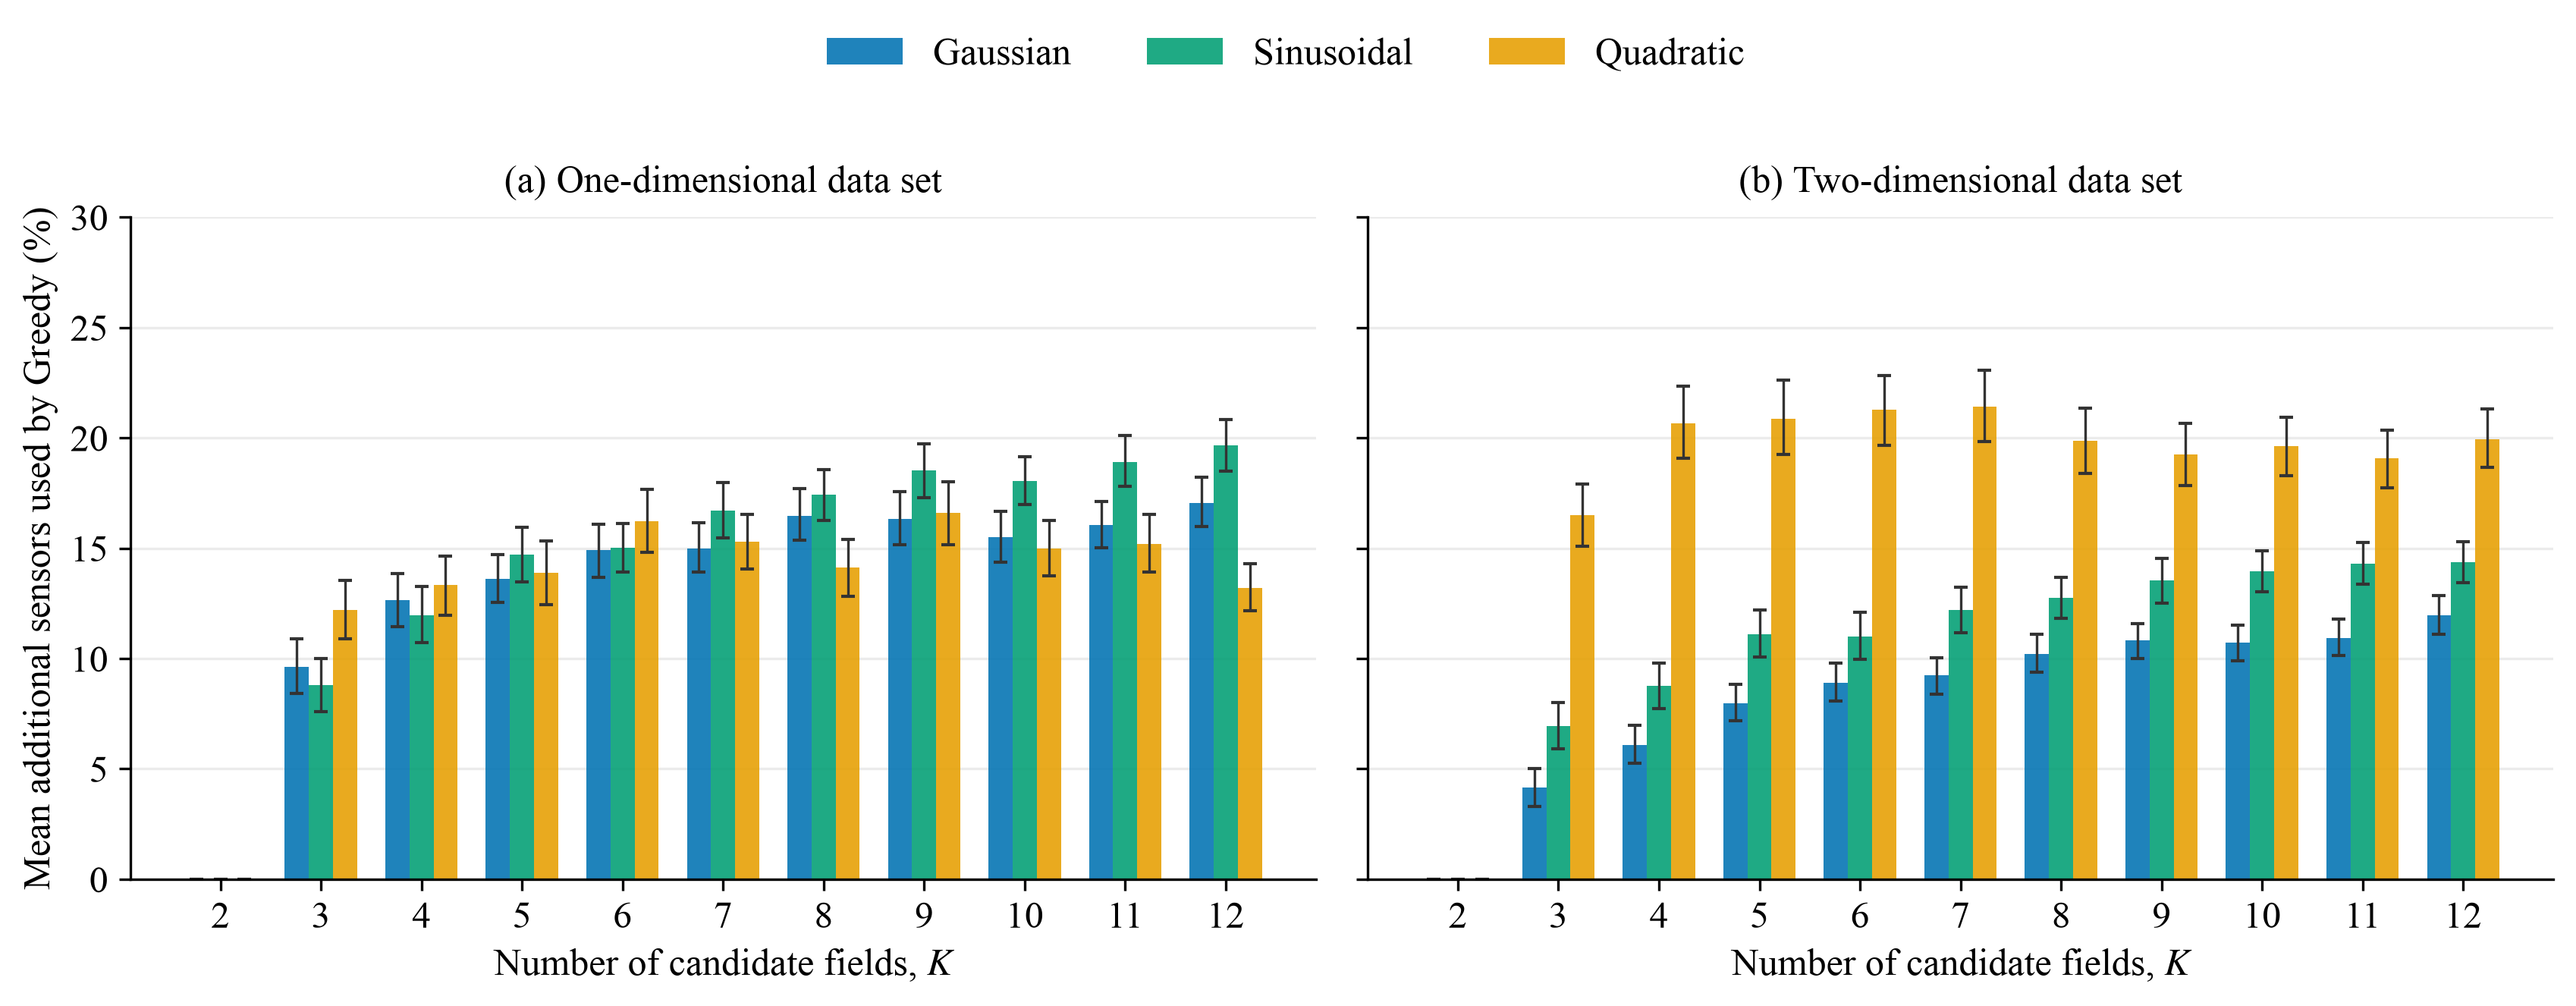

Displaying guarantee: /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/problem-1-zero-error/results/methods/full/figures/benchmark_guarantee_comparison.png


### Approximation guarantee comparison

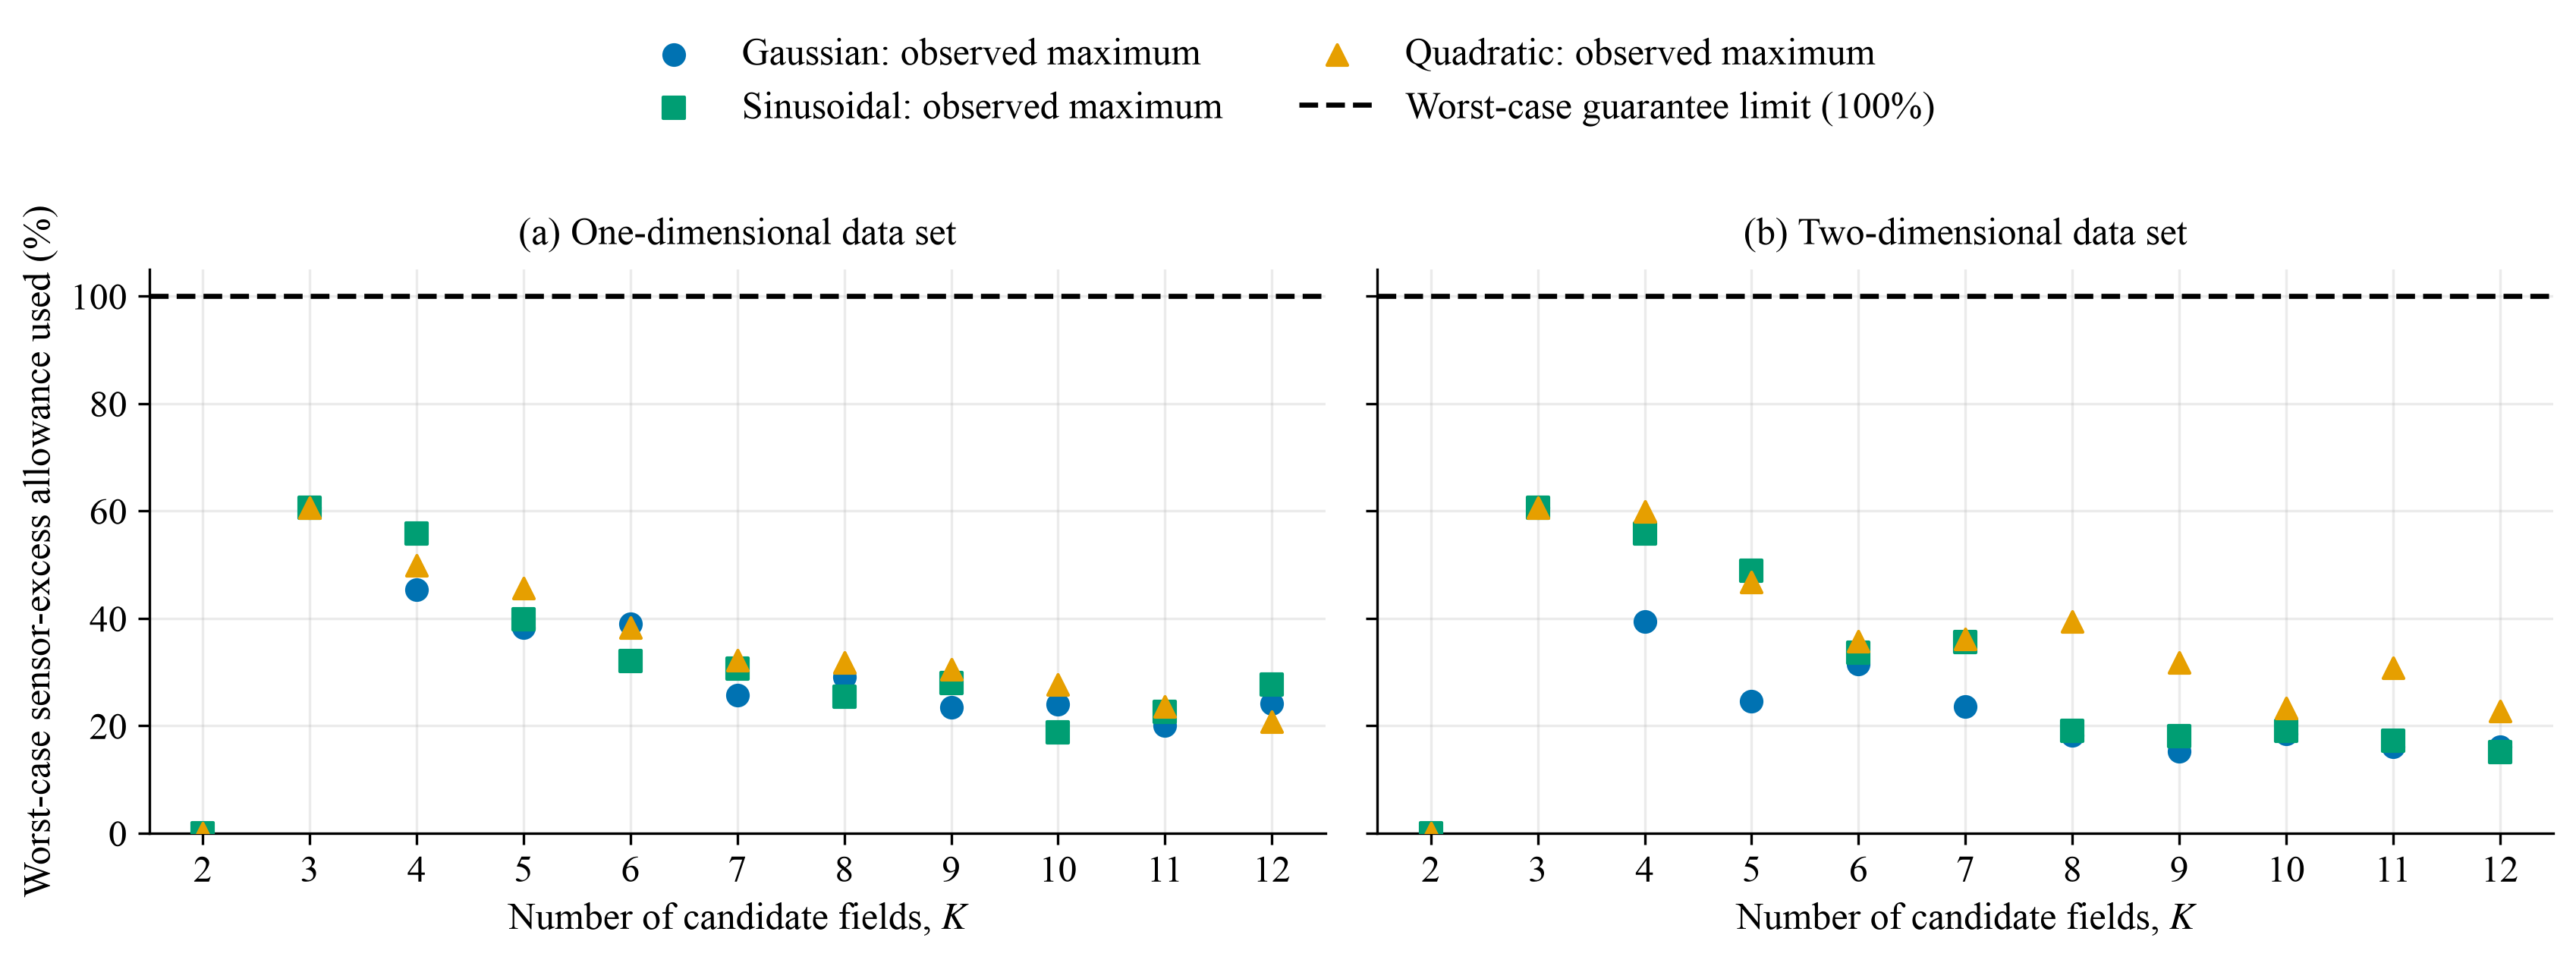

Displaying heatmaps: /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/problem-1-zero-error/results/methods/full/figures/benchmark_quality_heatmaps.png


### Quality heatmaps

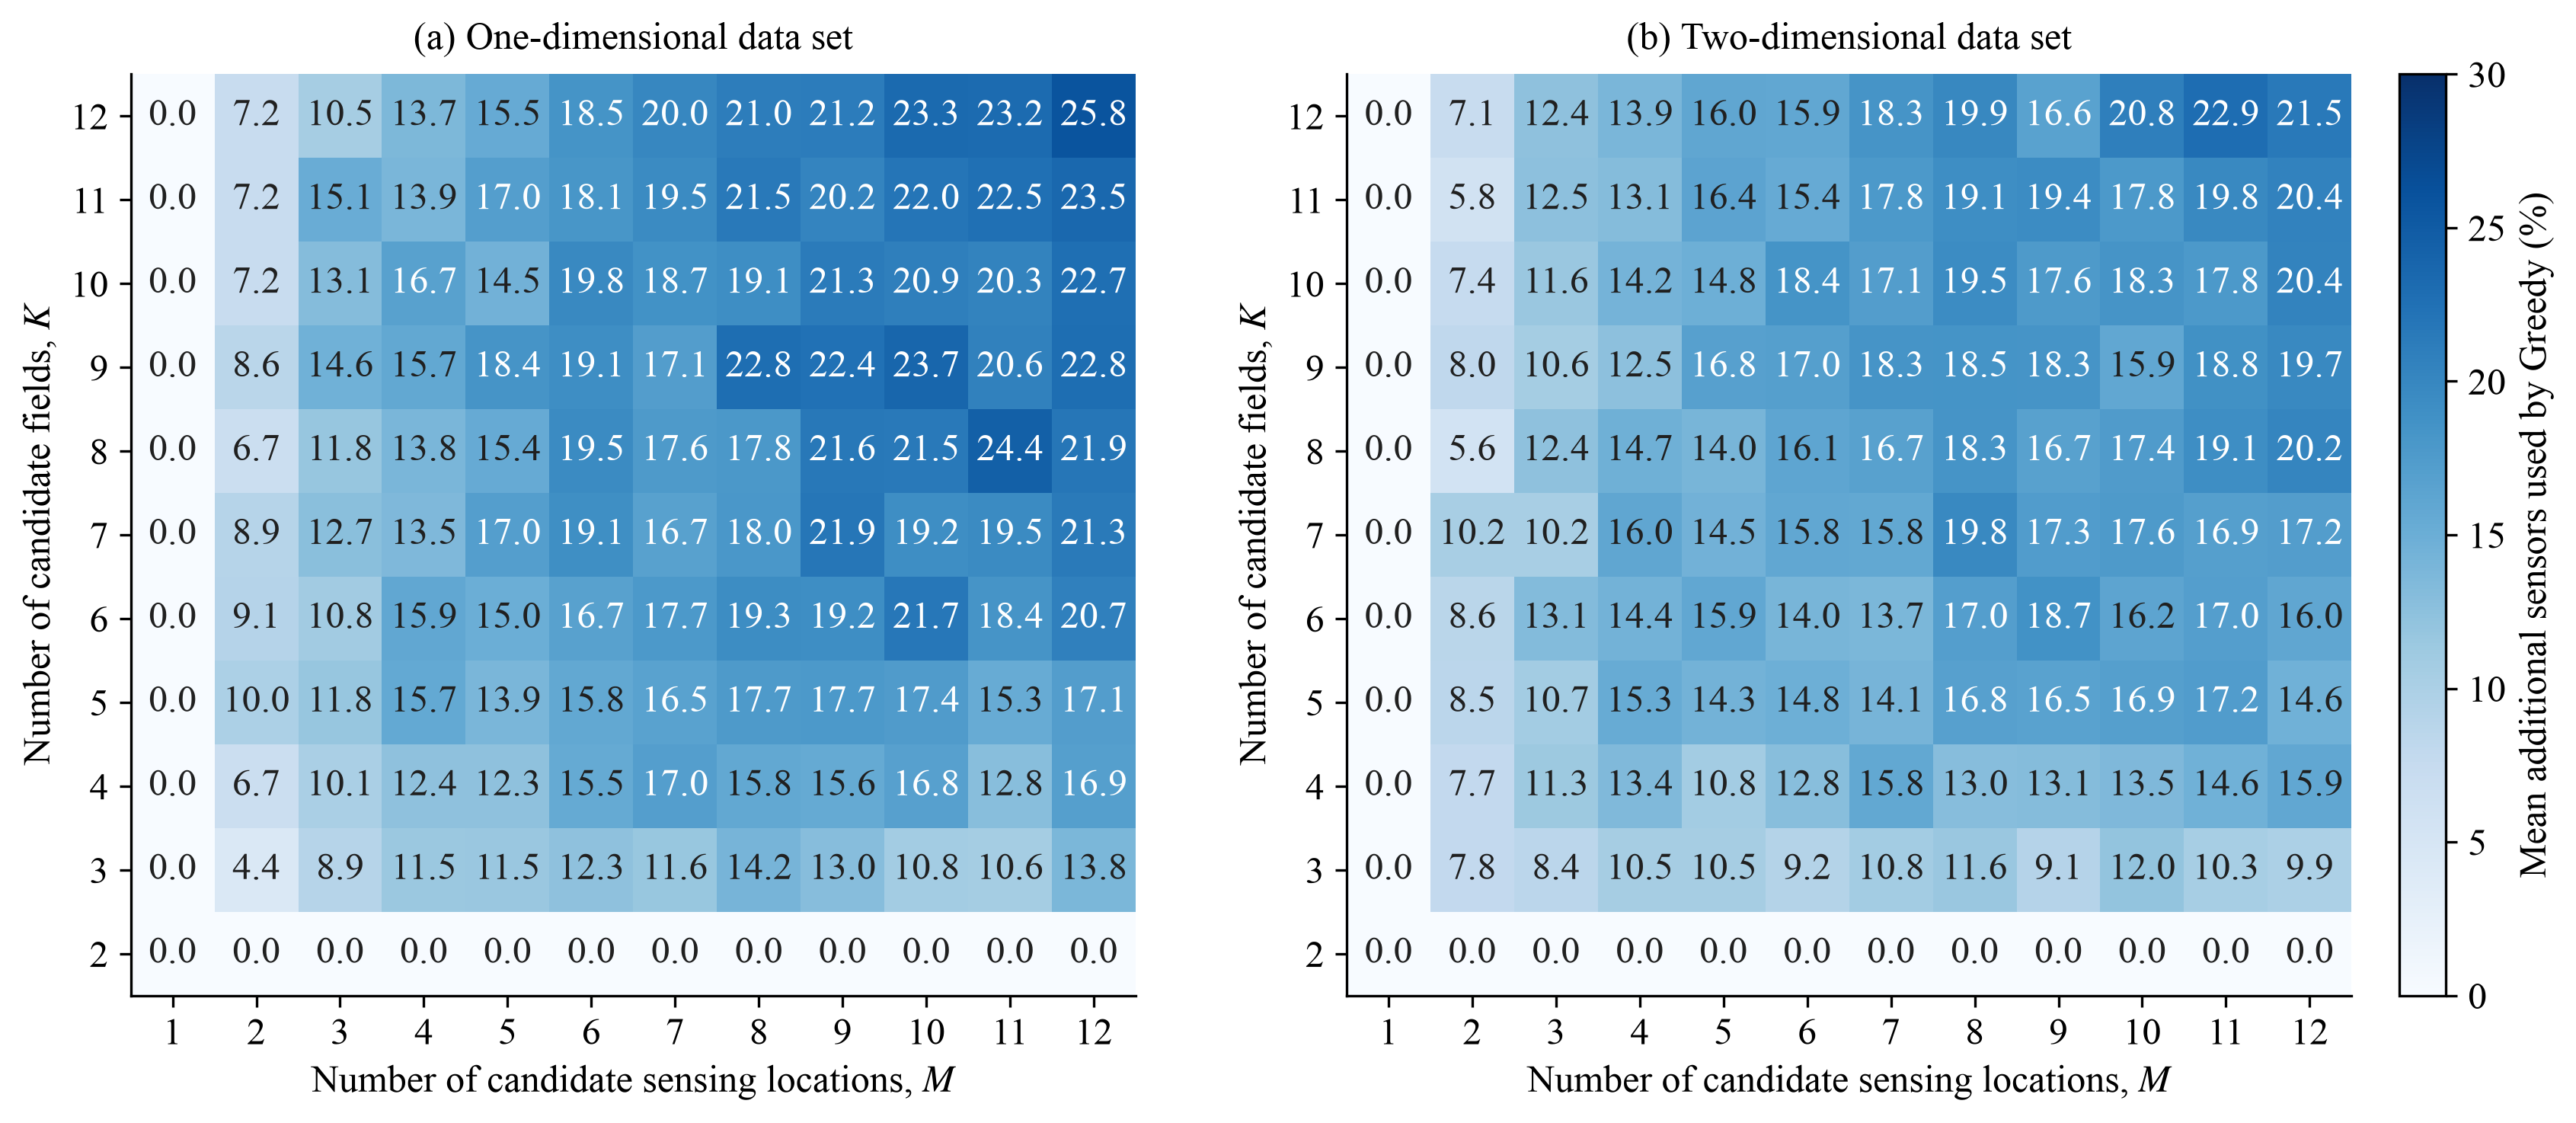

In [13]:
PUBLICATION_FIGURES = ("families", "guarantee", "heatmaps")
plot_titles = {
    "families": "Sensor excess by field family",
    "guarantee": "Approximation guarantee comparison",
    "heatmaps": "Quality heatmaps",
}
plot_files = {
    "families": "benchmark_family_excess.png",
    "guarantee": "benchmark_guarantee_comparison.png",
    "heatmaps": "benchmark_quality_heatmaps.png",
}
figure_directory = Path(analysis["output_directory"]) / "figures"
print("Displaying solution-method figures from:", figure_directory)
for figure_key in PUBLICATION_FIGURES:
    figure_path = figure_directory / plot_files[figure_key]
    print(f"Displaying {figure_key}: {figure_path}")
    display(Markdown(f"### {plot_titles[figure_key]}"))
    display(Image(filename=str(figure_path)))


## Allocation agreement

Families and location counts are pooled at each K. “Same allocation” compares sensor counts at every location; “same total budget” compares their sums. Different allocations can both be optimal, so agreement is measured against the particular DP solution returned.


| Dimension | K | Cases | Allocation matches | Budget matches | Same allocation (%) | Same total budget (%) |
|---|---:|---:|---:|---:|---:|---:|
| One-dimensional | 2 | 1800 | 1035 | 1800 | 57.50 | 100.00 |
| One-dimensional | 3 | 1800 | 748 | 1135 | 41.56 | 63.06 |
| One-dimensional | 4 | 1800 | 644 | 858 | 35.78 | 47.67 |
| One-dimensional | 5 | 1800 | 516 | 679 | 28.67 | 37.72 |
| One-dimensional | 6 | 1800 | 459 | 567 | 25.50 | 31.50 |
| One-dimensional | 7 | 1800 | 434 | 511 | 24.11 | 28.39 |
| One-dimensional | 8 | 1800 | 422 | 485 | 23.44 | 26.94 |
| One-dimensional | 9 | 1800 | 393 | 436 | 21.83 | 24.22 |
| One-dimensional | 10 | 1800 | 369 | 419 | 20.50 | 23.28 |
| One-dimensional | 11 | 1800 | 352 | 392 | 19.56 | 21.78 |
| One-dimensional | 12 | 1800 | 364 | 397 | 20.22 | 22.06 |
| Two-dimensional | 2 | 1800 | 1220 | 1800 | 67.78 | 100.00 |
| Two-dimensional | 3 | 1800 | 910 | 1200 | 50.56 | 66.67 |
| Two-dimensional | 4 | 1800 | 744 | 938 | 41.33 | 52.11 |
| Two-dimensional | 5 | 1800 | 605 | 738 | 33.61 | 41.00 |
| Two-dimensional | 6 | 1800 | 555 | 653 | 30.83 | 36.28 |
| Two-dimensional | 7 | 1800 | 468 | 565 | 26.00 | 31.39 |
| Two-dimensional | 8 | 1800 | 436 | 514 | 24.22 | 28.56 |
| Two-dimensional | 9 | 1800 | 408 | 474 | 22.67 | 26.33 |
| Two-dimensional | 10 | 1800 | 377 | 421 | 20.94 | 23.39 |
| Two-dimensional | 11 | 1800 | 376 | 422 | 20.89 | 23.44 |
| Two-dimensional | 12 | 1800 | 355 | 396 | 19.72 | 22.00 |

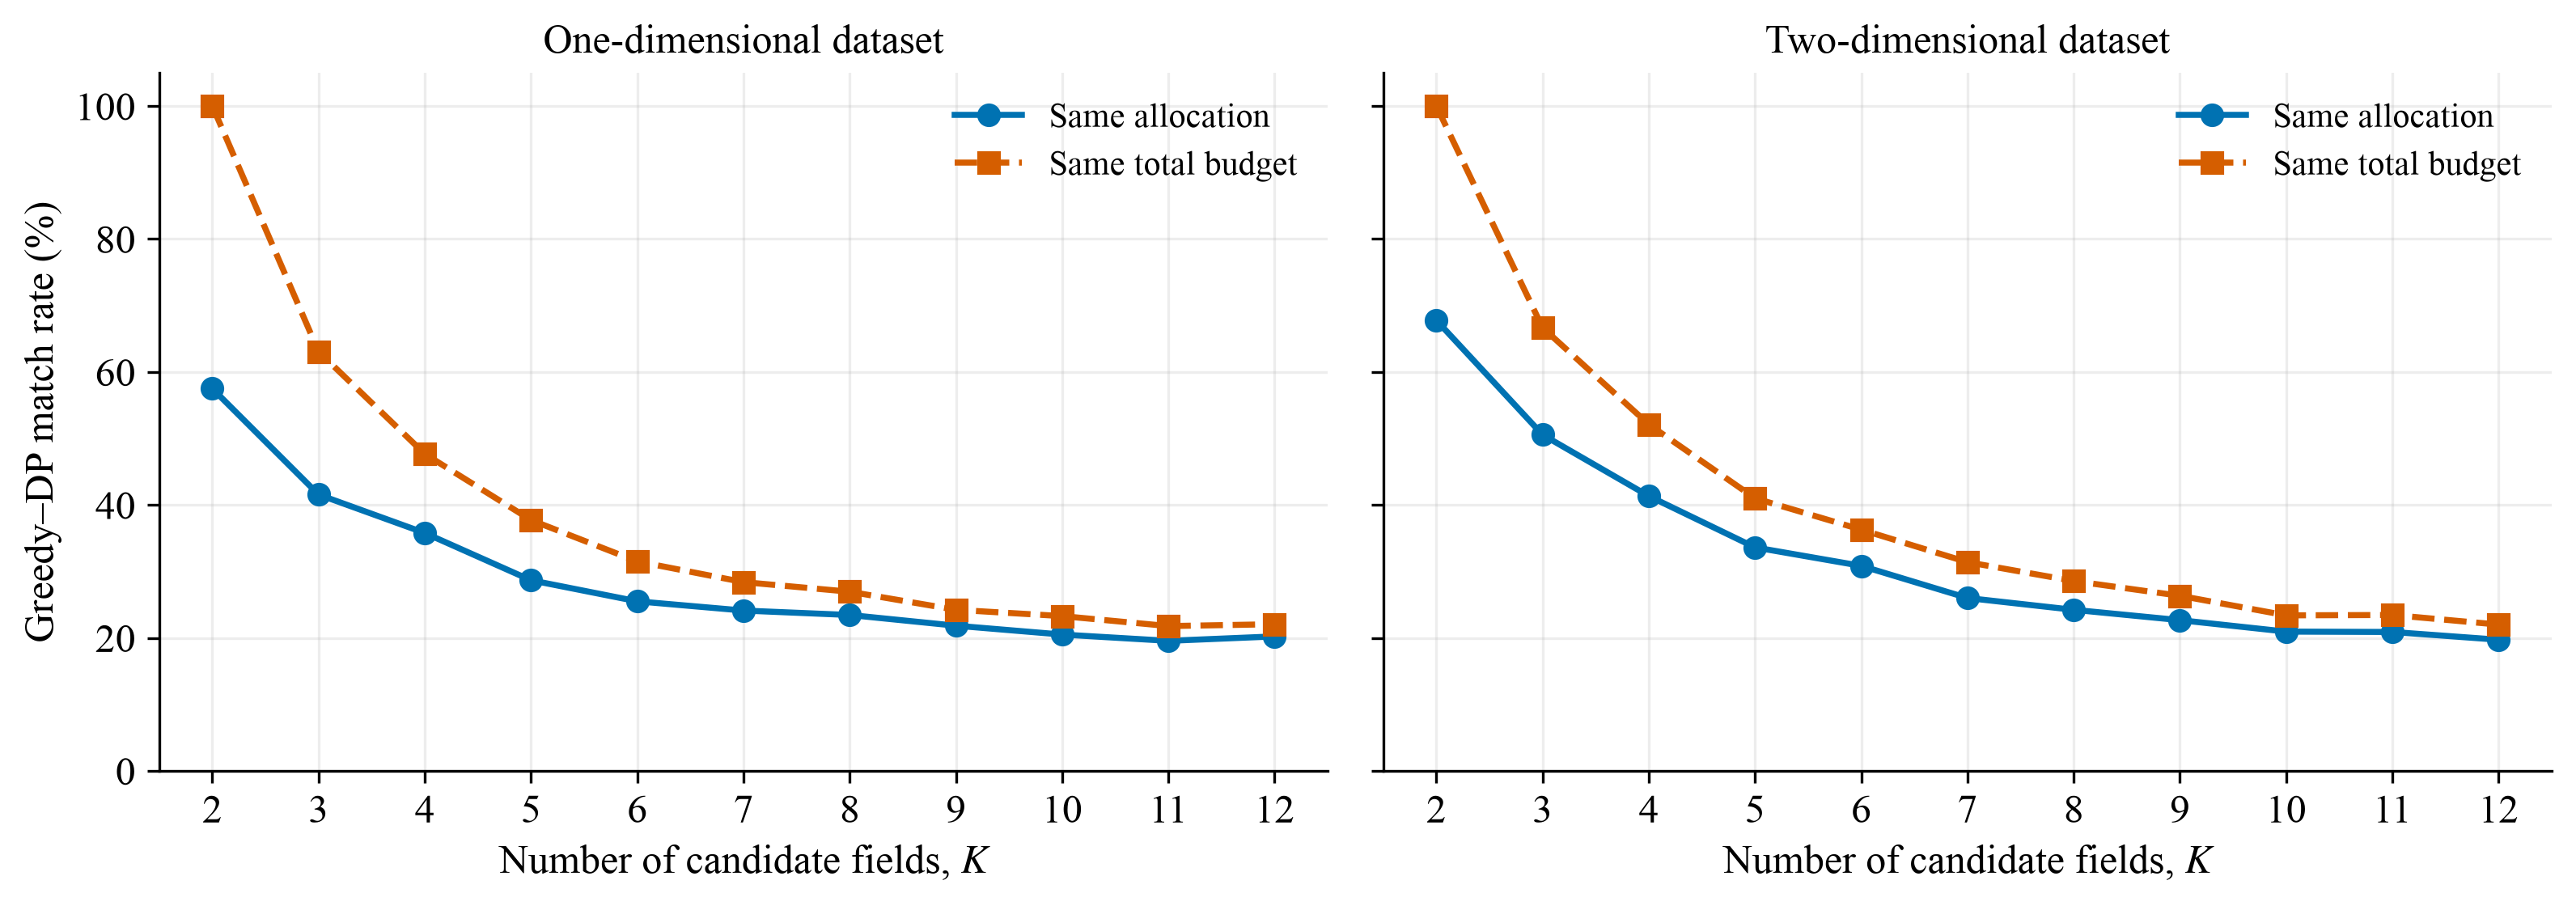

Saved table: /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/problem-1-zero-error/results/methods/full/tables/allocation_match.csv


In [14]:
match_rows = analysis["allocation_match_table"]
display(Markdown(markdown_table(
    match_rows,
    (("Dimension", "dimension"), ("K", "K"), ("Cases", "case_count"),
     ("Allocation matches", "allocation_matches"), ("Budget matches", "budget_matches"),
     ("Same allocation (%)", "allocation_match_percent"),
     ("Same total budget (%)", "budget_match_percent")),
    {"K": lambda x: str(int(x)), "case_count": lambda x: str(int(x)),
     "allocation_matches": lambda x: str(int(x)), "budget_matches": lambda x: str(int(x)),
     "allocation_match_percent": lambda x: f"{float(x):.2f}",
     "budget_match_percent": lambda x: f"{float(x):.2f}"},
)))
match_figure_path = Path(analysis["output_directory"]) / "figures" / "allocation_match.png"
display(Image(filename=str(match_figure_path)))
print("Saved table:", Path(analysis["output_directory"]) / "tables" / "allocation_match.csv")


## Saved outputs

Results go to `results/methods/{test,full}/`, with combined `tables/` and `figures/` and per-dataset details in `1d/tables/` and `2d/tables/`.
